<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Procesamiento de Lenguaje Natural · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Subtarea 2: Tipo de Polarización con un Metamodelo por Idioma (SemEval-2026 Task 9)</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Pérez Martínez Ángel Noel, Zamora Antiga Ángel Javier</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Objetivo</span></div>

Identificar el tipo de polarización de cada texto (subtarea 2). Es un problema **multietiqueta** con cinco etiquetas (`political`, `racial/ethnic`, `religious`, `gender/sexual` y `other`), ya que un mismo texto puede atacar a varios grupos a la vez.

Se parte de lo aprendido en la subtarea 1. Entrenar un modelo por idioma fue la decisión que más pesó, y la regresión logística por idioma rindió igual que el voto suave con una fracción del costo. Por eso aquí se reutiliza el metamodelo `ClasificadorPorIdioma` con una regresión logística para cada etiqueta.

Puesto que un texto no polarizado nunca tiene tipo, hay dos maneras de aprovechar esa jerarquía, y se prueban las dos.

| | Entrenamiento | Predicción |
|:--|:--|:--|
| **Opción A** | Solo con los textos polarizados | Solo sobre los textos que la subtarea 1 marca como polarizados, el resto recibe ceros (cascada) |
| **Opción B** | Con todos los textos | Sobre todos los textos, con y sin la cascada de la subtarea 1 |

Además, cada opción se entrena de dos formas. La primera es la **relevancia binaria**, con un clasificador independiente por etiqueta. La segunda es una **cadena de clasificadores**, donde cada etiqueta recibe como variables adicionales las etiquetas que ya se predijeron, para aprovechar que algunos tipos suelen aparecer juntos.

La métrica es el **F1 macro sobre las cinco etiquetas**, es decir, el promedio del F1 de la clase positiva de cada etiqueta. Se calcula sobre todo `test`, incluidos los textos no polarizados, porque así se evalúa la tarea completa y los errores de la subtarea 1 también cuentan. Igual que en la subtarea 1, el resumen principal es el promedio por idioma, que le da el mismo peso a cada uno.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Preparación de entorno</span></div>

In [1]:
# Manejo de datos
import os
import time
import joblib
import warnings
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import wilcoxon
from joblib import Parallel, delayed

# Modelos
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.validation import check_is_fitted
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import f1_score

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibilidad
random_state = 42

# Rutas y etiquetas de la subtarea
ruta_datos = 'data'
ruta_procesado = os.path.join(ruta_datos, 'procesado')
ruta_tfidf = os.path.join(ruta_datos, 'tfidf')
ruta_predicciones = os.path.join(ruta_datos, 'predicciones')
tipos = ['political', 'racial/ethnic', 'religious', 'gender/sexual', 'other']

warnings.filterwarnings('ignore', category = FutureWarning)

Se usan los textos limpios de `data/procesado/` y los vectorizadores TF-IDF de `data/tfidf/` (uno por idioma y uno global), que se ajustaron solo con `train` en la etapa de preprocesamiento.

Para la cascada se toman las predicciones de la subtarea 1 guardadas en `data/predicciones/task1_test.csv`, en concreto las de la regresión logística por idioma (`idioma_lr`), ya que fue el modelo que se recomendó en esa etapa. Se unen por `id` para no depender del orden de las filas.

Todos los hiperparámetros y umbrales se eligen con validación cruzada dentro de `train`, y `test` se usa una sola vez, al final, para comparar las configuraciones.

In [2]:
train = pd.read_csv(os.path.join(ruta_procesado, 'train.csv'))
test = pd.read_csv(os.path.join(ruta_procesado, 'test.csv')).drop(columns = ['canary'])
idiomas = sorted(train['idioma'].unique())

vectorizadores = joblib.load(os.path.join(ruta_tfidf, 'vectorizadores_idioma.joblib'))
vectorizador_global = joblib.load(os.path.join(ruta_tfidf, 'vectorizador_global.joblib'))

# Predicciones de la subtarea 1 (regresión logística por idioma)
subtarea1 = pd.read_csv(os.path.join(ruta_predicciones, 'task1_test.csv'))[['id', 'idioma_lr']]
test = test.merge(subtarea1, on = 'id', how = 'left', validate = 'one_to_one').rename(columns = {'idioma_lr': 'pol_subtarea1'})
assert test['pol_subtarea1'].notnull().all()

Y_train = train[tipos].to_numpy()
Y_test = test[tipos].to_numpy()
polarizado = train['polarization'].to_numpy() == 1

print(f'Tamaño de train: {train.shape}, polarizados: {polarizado.sum()}')
print(f'Tamaño de test: {test.shape}')
print(f"F1 macro de la subtarea 1 que alimenta la cascada: {f1_score(test['polarization'], test['pol_subtarea1'], average = 'macro'):.4f}")

Tamaño de train: (73454, 15), polarizados: 38977
Tamaño de test: (33288, 16)
F1 macro de la subtarea 1 que alimenta la cascada: 0.7834


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Etiquetas disponibles por idioma</span></div>

Entrenar un clasificador por idioma y por etiqueta solo tiene sentido si cada idioma tiene suficientes ejemplos de las dos clases de cada etiqueta. En el análisis exploratorio se vio que la distribución de los tipos cambia mucho entre idiomas, entonces antes de entrenar conviene revisar cuántos positivos y negativos tiene cada combinación.

Se cuentan en los dos escenarios de entrenamiento. En la opción A los negativos de una etiqueta son solo los textos polarizados que no la tienen, mientras que en la opción B también cuentan todos los textos no polarizados.

In [3]:
min_positivos = 30

def conteo_clases(Y, idioma):
    """
    Función que cuenta los positivos y negativos de cada etiqueta en cada idioma

    inputs:
    --------
        Y (numpy.ndarray): Matriz de etiquetas (textos x etiquetas)
        idioma (numpy.ndarray): Idioma de cada texto

    outputs:
    --------
        tuple: DataFrames de positivos y negativos, con idiomas en filas y etiquetas en columnas
    """
    positivos = pd.DataFrame(Y, columns = tipos).groupby(idioma).sum()
    negativos = pd.DataFrame(1 - Y, columns = tipos).groupby(idioma).sum()
    return positivos, negativos

pos_A, neg_A = conteo_clases(Y_train[polarizado], train.loc[polarizado, 'idioma'].to_numpy())
pos_B, neg_B = conteo_clases(Y_train, train['idioma'].to_numpy())
pos_test = pd.DataFrame(Y_test, columns = tipos).groupby(test['idioma'].to_numpy()).sum()

# Combinaciones idioma y etiqueta sin ejemplos suficientes
faltantes = []
for opcion, pos, neg in [('A', pos_A, neg_A), ('B', pos_B, neg_B)]:
    for i in idiomas:
        for t in tipos:
            if pos.loc[i, t] < min_positivos or neg.loc[i, t] < min_positivos:
                faltantes.append({'opción': opcion, 'idioma': i, 'etiqueta': t, 'positivos (train)': pos.loc[i, t],
                                  'negativos (train)': neg.loc[i, t], 'positivos (test)': pos_test.loc[i, t]})
display(pd.DataFrame(faltantes))

,opción,idioma,etiqueta,positivos (train),negativos (train),positivos (test)
0,A,amh,gender/sexual,19,2498,9
1,A,ben,racial/ethnic,25,1399,12
2,A,ben,gender/sexual,17,1407,8
3,A,eng,political,1147,25,518
4,A,hau,gender/sexual,29,363,14
5,A,hau,other,14,378,6
6,A,ita,political,0,1365,412
7,A,ita,other,0,1365,219
8,B,amh,gender/sexual,19,3312,9
9,B,ben,racial/ethnic,25,3308,12


Aparecen tres situaciones distintas.

* **Italiano.** No tiene ni un solo ejemplo de `political` ni de `other` en `train`, pero en `test` tiene 412 y 219. Debido a que un clasificador no puede aprender una clase que nunca vio, un modelo entrenado solo con textos en italiano nunca predeciría esas etiquetas y su F1 en ellas sería cero. Esto parece un cambio en el criterio de anotación entre particiones más que una característica del idioma.
* **Etiquetas raras.** En amhárico, bengalí y hausa algunas etiquetas tienen apenas entre 14 y 29 positivos, lo que es muy poco para elegir la regularización y el umbral con validación cruzada.
* **Inglés en la opción A.** Casi todos los textos polarizados en inglés son políticos, entonces al entrenar solo con polarizados quedan apenas 25 negativos de `political`.

Para estos casos se usa un **modelo global de respaldo**, entrenado con los textos de los 22 idiomas y el vectorizador global. Cuando una combinación de idioma y etiqueta tiene menos de 30 positivos o menos de 30 negativos, el metamodelo por idioma la marca como no disponible y su predicción se toma del modelo global. Se eligió 30 puesto que, con 3 particiones para el umbral y otras 3 internas para elegir `C`, deja alrededor de 7 positivos en cada partición interna, que es lo mínimo para que el F1 sea medianamente estable.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metamodelo</span></div>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Clasificador multietiqueta con umbral por etiqueta</span></div>

`Multietiqueta` entrena un clasificador binario para cada etiqueta y elige para cada una el umbral que maximiza su F1, ya que la métrica de la subtarea es el F1 de la clase positiva de cada etiqueta. Igual que el `VotoSuave` de la subtarea 1, el umbral se elige con probabilidades fuera de muestra obtenidas por validación cruzada, así que nunca se ajusta con predicciones sobre textos que el modelo ya vio.

Tiene dos parámetros propios de esta subtarea.

* `min_positivos`. Si una etiqueta no alcanza ese número de positivos y de negativos, no se entrena y su predicción se marca con `-1`, para que después la complete el modelo de respaldo.
* `cadena`. Si es `True`, las etiquetas se predicen en orden (`political`, `racial/ethnic`, `religious`, `gender/sexual`, `other`) y cada clasificador recibe como variables extra las etiquetas anteriores. Al entrenar se usan las etiquetas **predichas fuera de muestra** y no las verdaderas, debido a que al predecir el modelo solo tendrá las predichas, y si se entrena con las verdaderas aprende a confiar en ellas más de la cuenta.

Hereda de `BaseEstimator` y `ClassifierMixin`, entonces se puede usar como estimador base de `ClasificadorPorIdioma` sin cambiar nada.

In [4]:
umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)

def mejor_umbral(y, proba):
    """
    Función que elige el umbral de decisión que maximiza el F1 de la clase positiva

    inputs:
    --------
        y (numpy.ndarray): Etiquetas verdaderas
        proba (numpy.ndarray): Probabilidades estimadas de la clase positiva

    outputs:
    --------
        float: Umbral con mayor F1
    """
    f1 = [f1_score(y, (proba >= u).astype(int), zero_division = 0) for u in umbrales]
    return umbrales[np.argmax(f1)]


class Multietiqueta(BaseEstimator, ClassifierMixin):
    """
    Clasificador multietiqueta con un clasificador binario y un umbral ajustado por etiqueta, opcionalmente en cadena

    inputs:
    --------
        estimador: Clasificador binario de scikit-learn con método predict_proba
        cadena (bool): Si es True, cada etiqueta usa como variables las etiquetas anteriores ya predichas
        min_positivos (int): Mínimo de positivos y de negativos para entrenar una etiqueta
        cv (int): Cantidad de particiones para estimar los umbrales
        random_state (int): Semilla de las particiones

    outputs:
    --------
        Atributos tras el ajuste: modelos_ y umbrales_ (dicts con el índice de la etiqueta como llave),
        disponibles_ (etiquetas entrenadas), n_etiquetas_, classes_
    """
    def __init__(self, estimador, cadena = False, min_positivos = 30, cv = 3, random_state = 42):
        self.estimador = estimador
        self.cadena = cadena
        self.min_positivos = min_positivos
        self.cv = cv
        self.random_state = random_state

    def _ampliar(self, X, anteriores):
        if not self.cadena or not anteriores:
            return X
        return sparse.hstack([X, sparse.csr_matrix(np.column_stack(anteriores).astype(np.float32))], format = 'csr')

    def fit(self, X, Y):
        Y = np.asarray(Y)
        self.n_etiquetas_ = Y.shape[1]
        self.classes_ = np.array([0, 1])
        positivos = Y.sum(axis = 0)
        self.disponibles_ = (positivos >= self.min_positivos) & (len(Y) - positivos >= self.min_positivos)

        particiones = StratifiedKFold(self.cv, shuffle = True, random_state = self.random_state)
        self.modelos_, self.umbrales_ = {}, {}
        anteriores = []
        for j in np.flatnonzero(self.disponibles_):
            Xj = self._ampliar(X, anteriores)
            proba = cross_val_predict(clone(self.estimador), Xj, Y[:, j], cv = particiones, method = 'predict_proba')[:, 1]
            self.umbrales_[j] = mejor_umbral(Y[:, j], proba)
            self.modelos_[j] = clone(self.estimador).fit(Xj, Y[:, j])
            if self.cadena:
                anteriores.append((proba >= self.umbrales_[j]).astype(int))
        return self

    def _recorrer(self, X):
        check_is_fitted(self)
        proba = np.full((X.shape[0], self.n_etiquetas_), np.nan)
        pred = np.full((X.shape[0], self.n_etiquetas_), -1, dtype = int)
        anteriores = []
        for j, modelo in self.modelos_.items():
            proba[:, j] = modelo.predict_proba(self._ampliar(X, anteriores))[:, 1]
            pred[:, j] = (proba[:, j] >= self.umbrales_[j]).astype(int)
            if self.cadena:
                anteriores.append(pred[:, j])
        return proba, pred

    def predict_proba(self, X):
        return self._recorrer(X)[0]

    def predict(self, X):
        return self._recorrer(X)[1]

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Clasificador por idioma y modelo global</span></div>

`ClasificadorPorIdioma` es el mismo metamodelo de la subtarea 1, sin cambios. Recibe un `DataFrame` con las columnas `texto` e `idioma`, entrena una copia del estimador base para cada idioma y al predecir envía cada texto al modelo de su idioma, conservando el orden de las filas. Como el estimador base ahora es un `Multietiqueta`, cada idioma tiene sus propios cinco clasificadores y sus propios cinco umbrales.

`ClasificadorGlobal` es su contraparte con un solo modelo. Recibe el mismo `DataFrame`, transforma todos los textos con el vectorizador global y entrena un único estimador. Se usa como respaldo y también como referencia, para confirmar que en esta subtarea entrenar por idioma sigue siendo mejor.

Finalmente, dos funciones combinan las predicciones. `completar_con_respaldo` sustituye los `-1` del modelo por idioma con la predicción del modelo global, y `aplicar_cascada` pone en cero las cinco etiquetas de los textos que la subtarea 1 considera no polarizados.

In [5]:
def ajustar_idioma(estimador, vectorizador, textos, y):
    """
    Función que vectoriza los textos de un idioma y entrena su clasificador

    inputs:
    --------
        estimador: Clasificador de scikit-learn sin entrenar
        vectorizador (TfidfVectorizer): Vectorizador ya ajustado del idioma
        textos (numpy.ndarray): Textos limpios del idioma
        y (numpy.ndarray): Etiquetas

    outputs:
    --------
        Clasificador entrenado
    """
    warnings.filterwarnings('ignore', category = FutureWarning)
    return estimador.fit(vectorizador.transform(textos), y)


class ClasificadorPorIdioma(BaseEstimator, ClassifierMixin):
    """
    Metamodelo que entrena un clasificador por idioma y envía cada texto al modelo de su idioma

    inputs:
    --------
        vectorizadores (dict): Vectorizadores ya ajustados, con el código de idioma como llave
        estimador: Clasificador de scikit-learn que se copia y entrena para cada idioma
        n_jobs (int): Cantidad de idiomas que se entrenan en paralelo (-1 usa todos los núcleos)

    outputs:
    --------
        Atributos tras el ajuste: modelos_ (dict con un clasificador entrenado por idioma), idiomas_, classes_
    """
    def __init__(self, vectorizadores, estimador, n_jobs = None):
        self.vectorizadores = vectorizadores
        self.estimador = estimador
        self.n_jobs = n_jobs

    @staticmethod
    def _separar(X):
        return X['texto'].to_numpy(), X['idioma'].to_numpy()

    @staticmethod
    def _validar_idiomas(idiomas, disponibles):
        faltantes = set(idiomas) - set(disponibles)
        if faltantes:
            raise ValueError(f'No hay modelo para los idiomas: {sorted(faltantes)}')

    def fit(self, X, y):
        textos, idiomas = self._separar(X)
        y = np.asarray(y)
        self._validar_idiomas(idiomas, self.vectorizadores)
        self.idiomas_ = sorted(set(idiomas))
        self.classes_ = np.unique(y)

        modelos = Parallel(n_jobs = self.n_jobs)(
            delayed(ajustar_idioma)(clone(self.estimador), self.vectorizadores[i], textos[idiomas == i], y[idiomas == i])
            for i in self.idiomas_)
        self.modelos_ = dict(zip(self.idiomas_, modelos))
        return self

    def _aplicar(self, metodo, X):
        check_is_fitted(self)
        textos, idiomas = self._separar(X)
        self._validar_idiomas(idiomas, self.modelos_)
        salida = None
        for i in np.unique(idiomas):
            filas = idiomas == i
            resultado = getattr(self.modelos_[i], metodo)(self.vectorizadores[i].transform(textos[filas]))
            if salida is None:
                salida = np.empty((len(textos),) + resultado.shape[1:], dtype = resultado.dtype)
            salida[filas] = resultado
        return salida

    def predict_proba(self, X):
        return self._aplicar('predict_proba', X)

    def predict(self, X):
        return self._aplicar('predict', X)


class ClasificadorGlobal(BaseEstimator, ClassifierMixin):
    """
    Modelo único para todos los idiomas, con la misma interfaz que ClasificadorPorIdioma

    inputs:
    --------
        vectorizador (TfidfVectorizer): Vectorizador global ya ajustado
        estimador: Clasificador de scikit-learn sin entrenar

    outputs:
    --------
        Atributos tras el ajuste: modelo_ (clasificador entrenado), classes_
    """
    def __init__(self, vectorizador, estimador):
        self.vectorizador = vectorizador
        self.estimador = estimador

    def fit(self, X, y):
        self.modelo_ = clone(self.estimador).fit(self.vectorizador.transform(X['texto']), y)
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        check_is_fitted(self)
        return self.modelo_.predict_proba(self.vectorizador.transform(X['texto']))

    def predict(self, X):
        check_is_fitted(self)
        return self.modelo_.predict(self.vectorizador.transform(X['texto']))


def completar_con_respaldo(pred_idioma, pred_global):
    """
    Función que sustituye las etiquetas sin modelo por idioma (-1) con la predicción del modelo global

    inputs:
    --------
        pred_idioma (numpy.ndarray): Predicciones del metamodelo por idioma, con -1 donde no hay modelo
        pred_global (numpy.ndarray): Predicciones del modelo global

    outputs:
    --------
        numpy.ndarray: Predicciones completas
    """
    pred = pred_idioma.copy()
    faltan = pred == -1
    pred[faltan] = pred_global[faltan]
    return pred


def aplicar_cascada(pred, polarizado):
    """
    Función que asigna cero a todas las etiquetas de los textos no polarizados

    inputs:
    --------
        pred (numpy.ndarray): Predicciones multietiqueta
        polarizado (numpy.ndarray): Polarización de cada texto (predicha o real)

    outputs:
    --------
        numpy.ndarray: Predicciones con la jerarquía aplicada
    """
    pred = pred.copy()
    pred[np.asarray(polarizado) == 0] = 0
    return pred

Antes de entrenar se comprueban dos cosas con una muestra de tres idiomas. La primera es que el enrutamiento siga conservando el orden ahora que cada predicción es un vector de cinco etiquetas. La segunda es que las etiquetas sin datos suficientes queden marcadas con `-1`, que en la opción A deberían ser `political` en inglés y `political` y `other` en italiano.

In [6]:
muestra = train[polarizado & train['idioma'].isin(['eng', 'ita', 'spa'])]
prueba = ClasificadorPorIdioma(vectorizadores, Multietiqueta(LogisticRegression(max_iter = 1000), cadena = True)).fit(muestra, muestra[tipos])

mezcla = test[test['idioma'].isin(['eng', 'ita', 'spa'])].sample(frac = 1, random_state = random_state)
a_mano = np.vstack([prueba.modelos_[i].predict(vectorizadores[i].transform([t]))
                    for t, i in zip(mezcla['texto'], mezcla['idioma'])])
print(f"Primeros idiomas de la muestra: {list(mezcla['idioma'].head(8))}")
print(f'Predicciones idénticas a las hechas a mano: {np.array_equal(prueba.predict(mezcla), a_mano)}')
display(pd.DataFrame({i: prueba.modelos_[i].disponibles_ for i in prueba.idiomas_}, index = tipos).T
        .replace({True: 'entrenada', False: 'respaldo (-1)'}))

Primeros idiomas de la muestra: ['spa', 'spa', 'ita', 'eng', 'spa', 'eng', 'ita', 'eng']


Predicciones idénticas a las hechas a mano: True


,political,racial/ethnic,religious,gender/sexual,other
eng,respaldo (-1),entrenada,entrenada,entrenada,entrenada
ita,respaldo (-1),entrenada,entrenada,entrenada,respaldo (-1)
spa,entrenada,entrenada,entrenada,entrenada,entrenada


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Entrenamiento</span></div>

Configuración de los modelos.

* **Regresión logística.** `LogisticRegressionCV` elige la regularización `C` entre 0.3, 1, 3, 10 y 30 con validación cruzada de 3 particiones, igual que en la subtarea 1. La diferencia es que ahora maximiza el F1 de la clase positiva, puesto que es lo que mide la subtarea. Con `class_weight = 'balanced'` los positivos pesan lo mismo que los negativos, lo cual importa porque etiquetas como `gender/sexual` aparecen en menos del 5% de los textos.
* **Umbral por etiqueta.** Se elige con validación cruzada de 3 particiones dentro de `Multietiqueta`, de forma independiente en cada idioma y en cada etiqueta.
* **Modelos por idioma.** Se entrenan cuatro, que resultan de combinar la opción A o B con la relevancia binaria o la cadena.
* **Modelos globales.** Se entrenan dos con relevancia binaria, uno con los textos polarizados (respaldo de la opción A) y otro con todos los textos (respaldo de la opción B).

Todo el entrenamiento tarda alrededor de 32 minutos, y casi 14 de ellos corresponden a los dos modelos globales.

In [7]:
def regresion_logistica(n_jobs = None):
    """
    Función que construye la regresión logística con búsqueda de C por validación cruzada

    inputs:
    --------
        n_jobs (int): Núcleos para la búsqueda de C

    outputs:
    --------
        LogisticRegressionCV: Clasificador sin entrenar
    """
    return LogisticRegressionCV(Cs = [0.3, 1, 3, 10, 30], cv = StratifiedKFold(3, shuffle = True, random_state = random_state),
                                scoring = 'f1', class_weight = 'balanced', max_iter = 3000, n_jobs = n_jobs)

tiempos = {}
train_A, Y_A = train[polarizado], Y_train[polarizado]

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Por idioma</span></div>

In [8]:
modelos_idioma = {}
for nombre, (X, Y, cadena) in {'A': (train_A, Y_A, False), 'A cadena': (train_A, Y_A, True),
                                'B': (train, Y_train, False), 'B cadena': (train, Y_train, True)}.items():
    inicio = time.perf_counter()
    modelos_idioma[nombre] = ClasificadorPorIdioma(vectorizadores, Multietiqueta(regresion_logistica(), cadena = cadena,
                                                                                min_positivos = min_positivos), n_jobs = -1).fit(X, Y)
    tiempos[nombre] = time.perf_counter() - inicio
    print(f'{nombre}: {tiempos[nombre] / 60:.1f} min')

A: 3.3 min


A cadena: 4.8 min


B: 4.0 min


B cadena: 5.6 min


In [9]:
# Umbral elegido en cada idioma y etiqueta (relevancia binaria)
for nombre in ['A', 'B']:
    tabla = pd.DataFrame({i: {tipos[j]: m.umbrales_.get(j, np.nan) for j in range(len(tipos))}
                          for i, m in modelos_idioma[nombre].modelos_.items()})
    print(f'\n\t Opción {nombre}: umbral por idioma y etiqueta (vacío = respaldo global)')
    display(tabla.round(2))


	 Opción A: umbral por idioma y etiqueta (vacío = respaldo global)


,amh,arb,ben,deu,eng,fas,hau,hin,ita,khm,...,ori,pan,pol,rus,spa,swa,tel,tur,urd,zho
political,0.22,0.46,0.08,0.13,NaN,0.47,0.46,0.31,NaN,0.43,...,0.36,0.41,0.13,0.49,0.44,0.49,0.27,0.46,0.05,0.47
racial/ethnic,0.48,0.47,NaN,0.48,0.49,0.41,0.49,0.50,0.50,0.44,...,0.48,0.51,0.48,0.33,0.48,0.34,0.46,0.48,0.05,0.43
religious,0.41,0.48,0.43,0.49,0.56,0.49,0.48,0.53,0.48,0.44,...,0.49,0.48,0.45,0.48,0.51,0.43,0.48,0.48,0.05,0.42
gender/sexual,NaN,0.48,NaN,0.48,0.47,0.42,NaN,0.42,0.40,0.42,...,0.47,0.48,0.46,0.47,0.42,0.51,0.11,0.47,0.05,0.49
other,0.48,0.50,0.48,0.48,0.53,0.52,NaN,0.42,NaN,0.43,...,0.55,0.47,0.45,0.47,0.50,0.51,0.11,0.44,0.05,0.48



	 Opción B: umbral por idioma y etiqueta (vacío = respaldo global)


,amh,arb,ben,deu,eng,fas,hau,hin,ita,khm,...,ori,pan,pol,rus,spa,swa,tel,tur,urd,zho
political,0.40,0.48,0.47,0.40,0.46,0.47,0.58,0.32,NaN,0.48,...,0.46,0.48,0.46,0.49,0.50,0.56,0.48,0.48,0.18,0.46
racial/ethnic,0.48,0.49,NaN,0.49,0.51,0.47,0.55,0.51,0.48,0.40,...,0.45,0.47,0.45,0.44,0.50,0.54,0.46,0.49,0.41,0.48
religious,0.47,0.46,0.43,0.48,0.45,0.51,0.53,0.48,0.50,0.43,...,0.51,0.42,0.43,0.47,0.49,0.59,0.47,0.49,0.43,0.38
gender/sexual,NaN,0.49,NaN,0.50,0.54,0.46,NaN,0.47,0.49,0.43,...,0.47,0.46,0.48,0.49,0.53,0.53,0.45,0.38,0.43,0.48
other,0.47,0.46,0.48,0.42,0.47,0.50,NaN,0.53,NaN,0.41,...,0.49,0.47,0.42,0.38,0.55,0.50,0.50,0.45,0.41,0.45


Los umbrales quedan casi siempre cerca de 0.5, lo esperable con `class_weight = 'balanced'`. Hay dos excepciones que vale la pena notar en la opción A. El urdu elige 0.05 en las cinco etiquetas, puesto que el 71% de sus textos polarizados tiene los cinco tipos y lo que más conviene es predecirlos todos. Además, `political` baja a 0.08 en bengalí y a 0.13 en alemán y polaco, ya que entre los polarizados de esos idiomas casi todo es político.

En la opción B estos extremos desaparecen, debido a que los textos no polarizados aportan muchos negativos y el modelo ya no gana nada prediciendo siempre la etiqueta.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Global</span></div>

In [10]:
modelos_global = {}
for nombre, (X, Y) in {'Global A': (train_A, Y_A), 'Global B': (train, Y_train)}.items():
    inicio = time.perf_counter()
    modelos_global[nombre] = ClasificadorGlobal(vectorizador_global, Multietiqueta(regresion_logistica(n_jobs = -1),
                                                                                    min_positivos = min_positivos)).fit(X, Y)
    tiempos[nombre] = time.perf_counter() - inicio
    m = modelos_global[nombre].modelo_
    print(f"{nombre}: {tiempos[nombre] / 60:.1f} min, umbrales = {dict(zip(tipos, m.umbrales_.values()))}")

Global A: 7.4 min, umbrales = {'political': np.float64(0.41), 'racial/ethnic': np.float64(0.5), 'religious': np.float64(0.55), 'gender/sexual': np.float64(0.55), 'other': np.float64(0.43)}


Global B: 6.4 min, umbrales = {'political': np.float64(0.48), 'racial/ethnic': np.float64(0.51), 'religious': np.float64(0.58), 'gender/sexual': np.float64(0.52), 'other': np.float64(0.54)}


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Evaluación en test</span></div>

Se arman las predicciones de cada configuración. Todas usan el respaldo global en las combinaciones sin datos suficientes, y la cascada usa la polarización predicha por la subtarea 1.

Además de las seis configuraciones que compiten, se calculan cuatro referencias que no son modelos utilizables pero ayudan a interpretar los resultados.

* **A con polarización real** (y su versión en cadena). Aplica la opción A con la polarización verdadera en lugar de la predicha. Es el resultado que se tendría con una subtarea 1 perfecta, así que mide cuánto se pierde por sus errores.
* **Global A + cascada** y **Global B.** Los modelos de respaldo usados solos, para comparar contra entrenar por idioma.

In [11]:
pol_subtarea1 = test['pol_subtarea1'].to_numpy()
pol_real = test['polarization'].to_numpy()

pred_global = {nombre: modelo.predict(test) for nombre, modelo in modelos_global.items()}
pred_cruda = {nombre: modelo.predict(test) for nombre, modelo in modelos_idioma.items()}
pred_completa = {nombre: completar_con_respaldo(pred, pred_global['Global ' + nombre[0]]) for nombre, pred in pred_cruda.items()}

predicciones = {
    'A + cascada': aplicar_cascada(pred_completa['A'], pol_subtarea1),
    'A cadena + cascada': aplicar_cascada(pred_completa['A cadena'], pol_subtarea1),
    'B': pred_completa['B'],
    'B + cascada': aplicar_cascada(pred_completa['B'], pol_subtarea1),
    'B cadena': pred_completa['B cadena'],
    'B cadena + cascada': aplicar_cascada(pred_completa['B cadena'], pol_subtarea1)
}
referencias = {
    'A con polarización real': aplicar_cascada(pred_completa['A'], pol_real),
    'A cadena con polarización real': aplicar_cascada(pred_completa['A cadena'], pol_real),
    'Global A + cascada': aplicar_cascada(pred_global['Global A'], pol_subtarea1),
    'Global B': pred_global['Global B']
}

def f1_por_idioma(pred):
    """
    Función que calcula el F1 macro sobre las cinco etiquetas en cada idioma

    inputs:
    --------
        pred (numpy.ndarray): Predicciones multietiqueta de todo test

    outputs:
    --------
        pandas.Series: F1 macro con el idioma como índice
    """
    return pd.Series({i: f1_score(Y_test[test['idioma'] == i], pred[test['idioma'] == i], average = 'macro', zero_division = 0)
                      for i in idiomas})

f1_test = pd.DataFrame({config: f1_por_idioma(pred) for config, pred in predicciones.items()})
f1_ref = pd.DataFrame({config: f1_por_idioma(pred) for config, pred in referencias.items()})

entrenamiento = {'A + cascada': 'A', 'A cadena + cascada': 'A cadena', 'B': 'B', 'B + cascada': 'B',
                 'B cadena': 'B cadena', 'B cadena + cascada': 'B cadena'}
resumen_test = pd.DataFrame({
    'F1 macro (promedio por idioma)': f1_test.mean(),
    'F1 macro (todo test)': pd.Series({c: f1_score(Y_test, p, average = 'macro', zero_division = 0) for c, p in predicciones.items()}),
    'idiomas donde es la mejor': f1_test.eq(f1_test.max(axis = 1), axis = 0).sum(),
    'tiempo de entrenamiento (min)': pd.Series({c: tiempos[m] / 60 for c, m in entrenamiento.items()})
})
display(resumen_test.round(4))

print('\n\t Referencias')
display(pd.DataFrame({
    'F1 macro (promedio por idioma)': f1_ref.mean(),
    'F1 macro (todo test)': pd.Series({c: f1_score(Y_test, p, average = 'macro', zero_division = 0) for c, p in referencias.items()})
}).round(4))

,F1 macro (promedio por idioma),F1 macro (todo test),idiomas donde es la mejor,tiempo de entrenamiento (min)
A + cascada,0.4957,0.6325,1,3.3460
A cadena + cascada,0.4886,0.6236,3,4.8348
B,0.4996,0.6271,10,3.9694
B + cascada,0.4899,0.6272,1,3.9694
B cadena,0.4974,0.6253,5,5.6222
B cadena + cascada,0.4870,0.6250,2,5.6222



	 Referencias


,F1 macro (promedio por idioma),F1 macro (todo test)
A con polarización real,0.6354,0.7645
A cadena con polarización real,0.6275,0.7544
Global A + cascada,0.4499,0.6298
Global B,0.4405,0.6305


,A + cascada,A cadena + cascada,B,B + cascada,B cadena,B cadena + cascada,A con polarización real,A cadena con polarización real,Global A + cascada,Global B
amh,0.469,0.462,0.476,0.474,0.485,0.475,0.557,0.552,0.378,0.451
arb,0.528,0.513,0.536,0.522,0.516,0.507,0.677,0.657,0.519,0.503
ben,0.267,0.260,0.282,0.282,0.290,0.265,0.343,0.340,0.237,0.239
deu,0.522,0.501,0.536,0.521,0.532,0.515,0.738,0.710,0.504,0.456
eng,0.456,0.451,0.419,0.435,0.430,0.444,0.572,0.575,0.429,0.360
fas,0.567,0.552,0.563,0.560,0.574,0.566,0.622,0.605,0.546,0.548
hau,0.260,0.268,0.241,0.240,0.242,0.236,0.527,0.546,0.239,0.180
hin,0.743,0.739,0.744,0.732,0.741,0.732,0.807,0.809,0.729,0.728
ita,0.220,0.184,0.245,0.203,0.237,0.200,0.343,0.291,0.189,0.220
khm,0.562,0.551,0.563,0.554,0.555,0.545,0.599,0.588,0.376,0.485


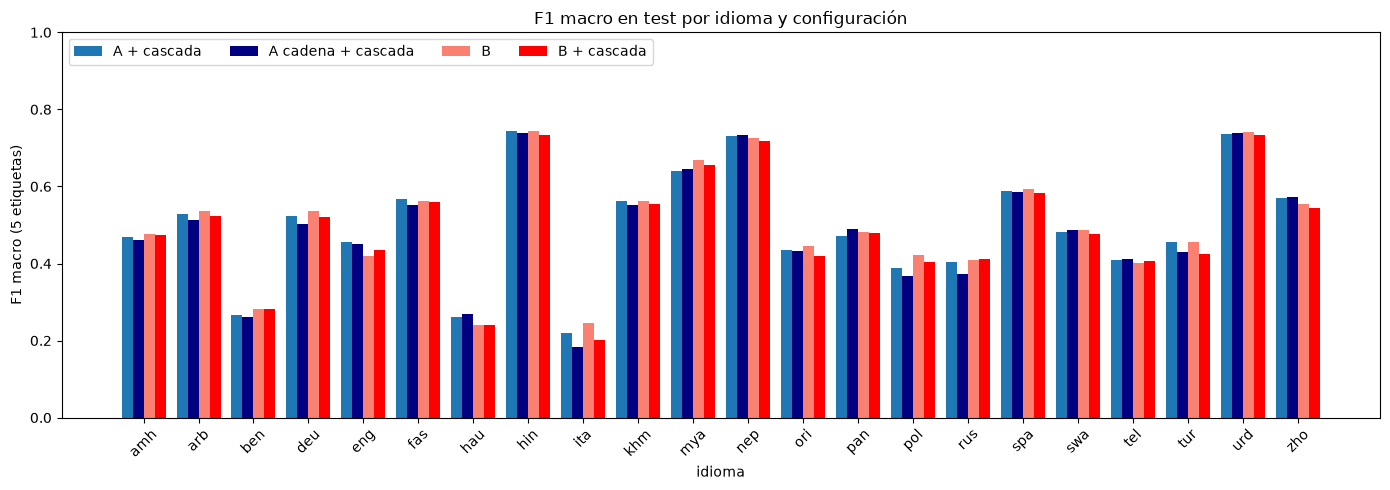

In [12]:
# F1 macro por idioma
display(pd.concat([f1_test, f1_ref], axis = 1).round(3))

x = np.arange(len(idiomas))
mostrar = ['A + cascada', 'A cadena + cascada', 'B', 'B + cascada']
colores = ['tab:blue', 'navy', 'salmon', 'red']

plt.figure(figsize = (14, 5))
for k, (config, color) in enumerate(zip(mostrar, colores)):
    plt.bar(x + (k - 1.5) * 0.2, f1_test[config], width = 0.2, color = color, label = config)
plt.xticks(x, idiomas, rotation = 45)
plt.ylim(0, 1)
plt.xlabel('idioma')
plt.ylabel('F1 macro (5 etiquetas)')
plt.title('F1 macro en test por idioma y configuración')
plt.legend(ncol = 4, loc = 'upper left')
plt.tight_layout()
plt.show()

In [13]:
# Diferencias pareadas por idioma
f1_todo = pd.concat([f1_test, f1_ref], axis = 1)
comparaciones = {
    'A + cascada vs. B': ('A + cascada', 'B'),
    'A + cascada vs. B + cascada': ('A + cascada', 'B + cascada'),
    'B + cascada vs. B': ('B + cascada', 'B'),
    'Cadena vs. relevancia binaria (A + cascada)': ('A cadena + cascada', 'A + cascada'),
    'Cadena vs. relevancia binaria (B)': ('B cadena', 'B'),
    'Cadena vs. relevancia binaria (B + cascada)': ('B cadena + cascada', 'B + cascada'),
    'Por idioma vs. global (A + cascada)': ('A + cascada', 'Global A + cascada'),
    'Por idioma vs. global (B)': ('B', 'Global B'),
    'Polarización real vs. predicha (A)': ('A con polarización real', 'A + cascada')
}
display(pd.DataFrame({nombre: {'diferencia media': (f1_todo[a] - f1_todo[b]).mean(),
                               'idiomas donde mejora': (f1_todo[a] > f1_todo[b]).sum(),
                               'p (Wilcoxon)': wilcoxon(f1_todo[a], f1_todo[b]).pvalue}
                      for nombre, (a, b) in comparaciones.items()}).T.round(4))

,diferencia media,idiomas donde mejora,p (Wilcoxon)
A + cascada vs. B,-0.0040,6.0,0.1129
A + cascada vs. B + cascada,0.0057,16.0,0.0542
B + cascada vs. B,-0.0097,3.0,0.0009
Cadena vs. relevancia binaria (A + cascada),-0.0071,8.0,0.0501
Cadena vs. relevancia binaria (B),-0.0022,10.0,0.8486
Cadena vs. relevancia binaria (B + cascada),-0.0029,11.0,0.4060
Por idioma vs. global (A + cascada),0.0457,22.0,0.0000
Por idioma vs. global (B),0.0591,22.0,0.0000
Polarización real vs. predicha (A),0.1398,22.0,0.0000


* **La opción B sin cascada es la mejor, aunque por muy poco.** Tiene el mayor F1 macro promedio por idioma (0.500) y es la mejor en 10 de los 22 idiomas. La opción A con cascada queda muy cerca (0.496) y la prueba de Wilcoxon no distingue entre las dos (p = 0.11). Si se mira todo `test` junto el orden se invierte (0.633 contra 0.627), lo que indica que A rinde mejor en los idiomas con más textos y B en el resto. En la práctica es un empate, entonces se prefiere B porque no depende de la subtarea 1 y funciona como un solo modelo.
* **La cascada empeora a la opción B.** Forzar ceros con la subtarea 1 baja el F1 casi un punto, empeora en 19 de los 22 idiomas y es la diferencia más clara de todas (p < 0.001). Esto pasa porque la subtarea 1 tiene sus propios errores (F1 macro de 0.78), y cada texto polarizado que marca como no polarizado pierde todos sus tipos aunque B los hubiera acertado. Como B ya aprendió de los textos no polarizados que esos textos no llevan tipo, la cascada solo le agrega los errores de otra etapa.
* **El cuello de botella es la detección de polarización.** Con la polarización real, la opción A llega a 0.635 de F1 macro promedio, 14 puntos más que con la predicha, y mejora en los 22 idiomas. Es decir, la mayor parte del error de la subtarea 2 no está en distinguir el tipo sino en decidir si el texto está polarizado.
* **La cadena de clasificadores no ayuda.** No mejora en ninguna de las tres comparaciones, y en la opción A incluso empeora 0.7 puntos (p = 0.05). Ni siquiera en urdu, donde los tipos casi siempre aparecen juntos, hay ganancia (0.732 contra 0.742 en B), ya que el umbral por idioma resuelve ese caso por sí solo al predecir todas las etiquetas a la vez. En cambio, la cadena propaga los errores, puesto que una etiqueta mal predicha al inicio se vuelve una variable equivocada para las siguientes.
* **Entrenar por idioma sigue siendo lo que más importa.** Supera al modelo global en los 22 idiomas, por 4.6 puntos en la opción A y 5.9 en la B, una ventaja mayor que en la subtarea 1. Tiene sentido, debido a que la distribución de los tipos cambia entre idiomas mucho más que la proporción de polarización.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Resultados por etiqueta</span></div>

In [14]:
# F1 de cada etiqueta sobre todo test
f1_etiqueta = pd.DataFrame({config: f1_score(Y_test, pred, average = None, zero_division = 0)
                            for config, pred in {**predicciones, **referencias}.items()}, index = tipos).T
display(f1_etiqueta.round(3))

,political,racial/ethnic,religious,gender/sexual,other
A + cascada,0.703,0.618,0.657,0.574,0.610
A cadena + cascada,0.703,0.608,0.633,0.566,0.607
B,0.710,0.620,0.648,0.575,0.584
B + cascada,0.700,0.615,0.644,0.578,0.598
B cadena,0.710,0.619,0.637,0.571,0.590
B cadena + cascada,0.700,0.612,0.637,0.573,0.603
A con polarización real,0.865,0.761,0.778,0.693,0.725
A cadena con polarización real,0.865,0.749,0.751,0.680,0.727
Global A + cascada,0.701,0.601,0.644,0.576,0.628
Global B,0.692,0.609,0.643,0.589,0.619


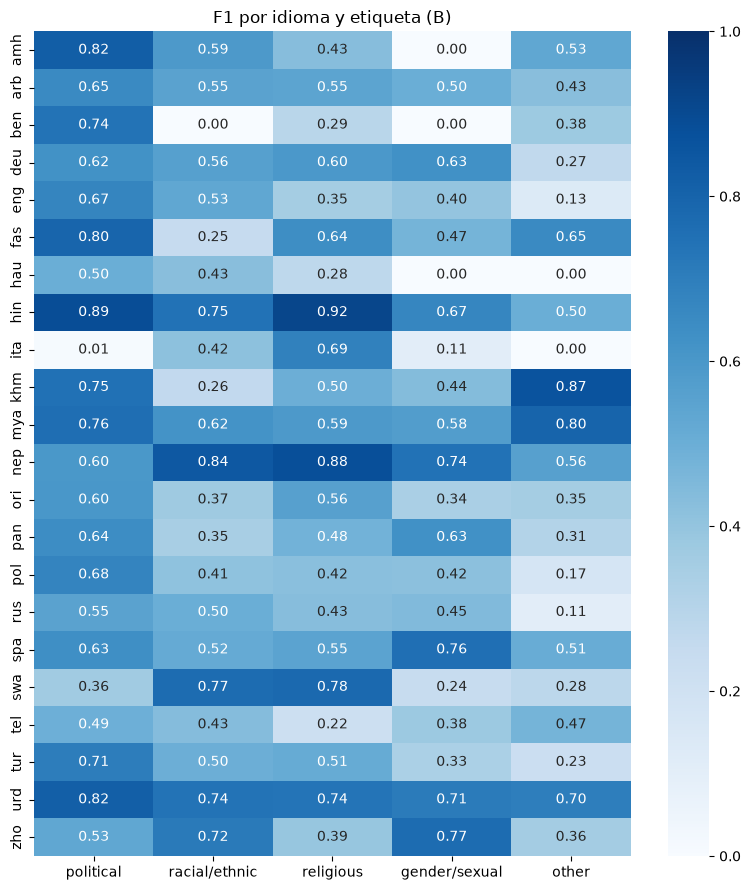

In [15]:
# F1 por idioma y etiqueta de la mejor configuración
mejor = resumen_test['F1 macro (promedio por idioma)'].idxmax()
f1_idioma_etiqueta = pd.DataFrame({i: f1_score(Y_test[test['idioma'] == i], predicciones[mejor][test['idioma'] == i],
                                               average = None, zero_division = 0) for i in idiomas}, index = tipos).T

plt.figure(figsize = (8, 9))
sns.heatmap(f1_idioma_etiqueta, annot = True, fmt = '.2f', cmap = 'Blues', vmin = 0, vmax = 1)
plt.title(f'F1 por idioma y etiqueta ({mejor})')
plt.tight_layout()
plt.show()

`political` es la etiqueta más fácil (F1 de 0.71 en la opción B) mientras que `gender/sexual` y `other` son las más difíciles (alrededor de 0.58). `other` junta todo lo que no cabe en las demás categorías, por lo que no tiene un vocabulario propio, y `gender/sexual` es la menos frecuente.

El mapa por idioma muestra que los F1 promedio más bajos (italiano 0.25, hausa 0.24 y bengalí 0.28) no se deben a que el modelo falle en todas las etiquetas, sino a que tiene uno o dos ceros. En bengalí, `racial/ethnic` y `gender/sexual` tienen 12 y 8 positivos en `test`. En hausa, `gender/sexual` y `other` tienen 14 y 6. En italiano, `political` y `other` nunca aparecen en `train`. Como el F1 macro le da el mismo peso a cada etiqueta, basta un cero para restarle 20 puntos al idioma.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Efecto del respaldo global</span></div>

Para medir cuánto aporta el respaldo, en las combinaciones de idioma y etiqueta que no tenían datos suficientes se compara el F1 con respaldo contra el que se obtendría si esas etiquetas simplemente se predijeran siempre como cero.

In [16]:
filas = []
for config, nombre, filtro in [('A + cascada', 'A', pol_subtarea1), ('B', 'B', None)]:
    cruda = pred_cruda[nombre]
    sin_respaldo = np.where(cruda == -1, 0, cruda)
    con_respaldo = pred_completa[nombre]
    if filtro is not None:
        sin_respaldo, con_respaldo = aplicar_cascada(sin_respaldo, filtro), aplicar_cascada(con_respaldo, filtro)
    for i, modelo in modelos_idioma[nombre].modelos_.items():
        es = (test['idioma'] == i).to_numpy()
        for j in np.flatnonzero(~modelo.disponibles_):
            filas.append({'configuración': config, 'idioma': i, 'etiqueta': tipos[j],
                          'positivos (test)': Y_test[es, j].sum(),
                          'F1 sin respaldo': f1_score(Y_test[es, j], sin_respaldo[es, j], zero_division = 0),
                          'F1 con respaldo': f1_score(Y_test[es, j], con_respaldo[es, j], zero_division = 0),
                          'F1 macro del idioma sin respaldo': f1_score(Y_test[es], sin_respaldo[es], average = 'macro', zero_division = 0),
                          'F1 macro del idioma con respaldo': f1_score(Y_test[es], con_respaldo[es], average = 'macro', zero_division = 0)})
display(pd.DataFrame(filas).round(3))

,configuración,idioma,etiqueta,positivos (test),F1 sin respaldo,F1 con respaldo,F1 macro del idioma sin respaldo,F1 macro del idioma con respaldo
0,A + cascada,amh,gender/sexual,9,0.0,0.000,0.469,0.469
1,A + cascada,ben,racial/ethnic,12,0.0,0.000,0.267,0.267
2,A + cascada,ben,gender/sexual,8,0.0,0.000,0.267,0.267
3,A + cascada,eng,political,518,0.0,0.686,0.319,0.456
4,A + cascada,hau,gender/sexual,14,0.0,0.118,0.237,0.260
5,A + cascada,hau,other,6,0.0,0.000,0.237,0.260
6,A + cascada,ita,political,412,0.0,0.019,0.215,0.220
7,A + cascada,ita,other,219,0.0,0.009,0.215,0.220
8,B,amh,gender/sexual,9,0.0,0.000,0.476,0.476
9,B,ben,racial/ethnic,12,0.0,0.000,0.282,0.282


El respaldo global solo rescata un caso, `political` en inglés para la opción A, que pasa de F1 cero a 0.69 y sube el F1 macro del inglés de 0.32 a 0.46. Ahí lo que faltaba eran negativos y no positivos, entonces el modelo global, que sí vio muchos textos no políticos, tiene algo que aportar.

En el resto no sirve. En amhárico, bengalí y hausa hay entre 6 y 14 positivos en `test`, demasiado pocos para que cualquier modelo acierte. En italiano el respaldo tampoco rescata `political` ni `other`, ya que el modelo global también aprendió con los textos italianos de `train`, donde esas etiquetas nunca aparecen, y termina asociando los n-gramas del italiano con su ausencia. Con estos datos ninguna variante supervisada puede predecir esas dos etiquetas en italiano, lo que deja su F1 macro con un techo de 0.6. Para una etapa posterior se podría entrenar el respaldo sin los textos italianos o usar una representación multilingüe que comparta significado entre idiomas.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Guardado</span></div>

Se guardan las predicciones de las seis configuraciones sobre `test` en `data/predicciones/task2_test.csv`, junto con el `id`, el idioma y las etiquetas verdaderas, para poder analizar errores sin volver a entrenar. Cada columna de predicción lleva el nombre corto de la configuración seguido de la etiqueta, por ejemplo `a_casc_political`.

In [17]:
os.makedirs(ruta_predicciones, exist_ok = True)
nombres = {'A + cascada': 'a_casc', 'A cadena + cascada': 'a_cad_casc', 'B': 'b', 'B + cascada': 'b_casc',
           'B cadena': 'b_cad', 'B cadena + cascada': 'b_cad_casc'}
salida = test[['id', 'idioma'] + tipos].copy()
for config, pred in predicciones.items():
    for j, t in enumerate(tipos):
        salida[f'{nombres[config]}_{t}'] = pred[:, j]
salida.to_csv(os.path.join(ruta_predicciones, 'task2_test.csv'), index = False)
print(f'Columnas guardadas: {salida.shape[1]}')
display(salida.head())

Columnas guardadas: 37


,id,idioma,political,racial/ethnic,religious,gender/sexual,other,a_casc_political,a_casc_racial/ethnic,a_casc_religious,...,b_cad_political,b_cad_racial/ethnic,b_cad_religious,b_cad_gender/sexual,b_cad_other,b_cad_casc_political,b_cad_casc_racial/ethnic,b_cad_casc_religious,b_cad_casc_gender/sexual,b_cad_casc_other
0,amh_00019453da74933d5b35f6dfb52761f3,amh,0,0,0,0,0,1,0,0,...,1,0,0,0,1,1,0,0,0,1
1,amh_000c3060ec412c2570a560d8b298989b,amh,0,1,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
2,amh_0028bfcc62a5a47ab6fdaf37f166b301,amh,1,0,0,1,0,1,1,0,...,1,1,0,0,0,1,1,0,0,0
3,amh_002b8ea7f4ecb837e03827565dd12ba2,amh,1,0,0,0,1,0,0,0,...,1,0,0,0,1,0,0,0,0,0
4,amh_00306c304d57dbf71dd492129eb08557,amh,1,0,0,0,0,1,0,0,...,1,0,0,0,0,1,0,0,0,0


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">F1 macro por idioma de la configuración elegida</span></div>

Esta tabla resume el resultado final de la subtarea 2 con la configuración recomendada, la opción B con relevancia binaria y sin cascada. Se calcula a partir de las predicciones guardadas en `data/predicciones/task2_test.csv`, así que no depende de los modelos en memoria.

El F1 macro de cada idioma sale de tres pasos.

1. Para cada etiqueta se comparan las predicciones con las etiquetas reales en todos los textos de `test` de ese idioma, incluidos los no polarizados, y se cuentan los verdaderos positivos ($VP$), los falsos positivos ($FP$) y los falsos negativos ($FN$).
2. Con esos conteos se obtiene el F1 de la clase positiva, $F_1 = \frac{2\,VP}{2\,VP + FP + FN}$, que es la media armónica entre la precisión y la exhaustividad. Los verdaderos negativos no entran en la fórmula, por eso un modelo que predice siempre cero obtiene un F1 de cero en esa etiqueta aunque acierte en casi todos los textos.
3. El F1 macro del idioma es el promedio simple de los cinco F1, de modo que cada etiqueta pesa lo mismo sin importar cuántos positivos tenga.

La última fila es el promedio de los 22 idiomas, el mismo valor que aparece como F1 macro promedio por idioma de la opción B en la evaluación.

In [18]:
# F1 de cada etiqueta y F1 macro por idioma de la opción B (relevancia binaria, sin cascada)
predichas = pd.read_csv(os.path.join(ruta_predicciones, 'task2_test.csv'))
columnas_b = [f'b_{t}' for t in tipos]

filas = {}
for i, g in predichas.groupby('idioma'):
    f1 = f1_score(g[tipos].to_numpy(), g[columnas_b].to_numpy(), average = None, zero_division = 0)
    filas[i] = {**dict(zip(tipos, f1)), 'F1 macro': f1.mean()}
tabla_idioma = pd.DataFrame(filas).T
tabla_idioma.loc['Promedio'] = tabla_idioma.mean()

display(tabla_idioma.style.format('{:.3f}').background_gradient(cmap = 'Blues', vmin = 0, vmax = 1))

,political,racial/ethnic,religious,gender/sexual,other,F1 macro
amh,0.822,0.591,0.433,0.000,0.535,0.476
arb,0.655,0.553,0.545,0.500,0.429,0.536
ben,0.741,0.000,0.292,0.000,0.377,0.282
deu,0.624,0.563,0.596,0.629,0.267,0.536
eng,0.672,0.532,0.354,0.400,0.135,0.419
fas,0.796,0.253,0.640,0.474,0.653,0.563
hau,0.500,0.427,0.277,0.000,0.000,0.241
hin,0.890,0.746,0.916,0.669,0.501,0.744
ita,0.010,0.415,0.690,0.107,0.000,0.245
khm,0.748,0.265,0.498,0.440,0.866,0.563


Leyendo la tabla por idioma se ve qué etiquetas sostienen o hunden cada F1 macro.

* **Hindi (0.744), urdu (0.742) y nepalí (0.726)** son los mejores, debido a que sus cinco etiquetas superan o rondan 0.5. En urdu las cinco quedan entre 0.70 y 0.82, ya que sus textos polarizados casi siempre tienen todos los tipos a la vez y el modelo los predice juntos. En hindi destacan `religious` (0.92) y `political` (0.89).
* **Birmano (0.670), español (0.594), persa (0.563), jemer (0.563) y chino (0.553)** tienen un nivel intermedio y parejo. El jemer y el birmano se apoyan en `other` (0.87 y 0.80), que es su tipo dominante, mientras que el persa baja por `racial/ethnic` (0.25), que casi no aparece en sus textos. El chino rinde mejor en `gender/sexual` y `racial/ethnic` (0.77 y 0.72) que en `political` (0.53), y el español destaca en `gender/sexual` (0.76).
* **Árabe y alemán (0.536), suajili (0.487), panyabí (0.482), amhárico (0.476), turco (0.456) y oriya (0.446)** quedan un poco por debajo de la media. En el suajili el tipo racial y el religioso funcionan bien (0.77 y 0.78) pero `political` y `gender/sexual` no (0.36 y 0.24). El amhárico tiene buen `political` (0.82), pero obtiene cero en `gender/sexual`, que solo tiene 9 positivos en `test`, y ese cero le quita casi 20 puntos.
* **Polaco (0.422), inglés (0.419), ruso (0.409) y telugu (0.401)** sufren sobre todo por `other`, que en polaco, inglés y ruso queda entre 0.11 y 0.17. En inglés casi todo lo polarizado es político, entonces las demás etiquetas tienen pocos positivos y el modelo las detecta mal.
* **Bengalí (0.282), italiano (0.245) y hausa (0.241)** son los peores, y en los tres el motivo es el mismo, etiquetas en cero. El bengalí tiene cero en `racial/ethnic` y `gender/sexual` (12 y 8 positivos en `test`), el hausa en `gender/sexual` y `other` (14 y 6 positivos) y el italiano en `other` y prácticamente en `political` (0.01), que nunca aparecen en `train`. Con dos etiquetas en cero, el F1 macro de un idioma no puede pasar de 0.6 aunque las otras tres fueran perfectas.

En resumen, el F1 macro por idioma depende menos de qué tan bien se modela cada idioma en general y más de si tiene suficientes ejemplos de las cinco etiquetas, puesto que una sola etiqueta en cero le resta 20 puntos.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

* Se construyó `Multietiqueta`, un clasificador con una regresión logística y un umbral propio por etiqueta, que puede trabajar como relevancia binaria o como cadena y marca las etiquetas sin datos suficientes para que las complete un modelo global. Se usó como estimador base del mismo `ClasificadorPorIdioma` de la subtarea 1, sin modificarlo.
* La opción B (entrenar con todos los textos, sin cascada) y la opción A (entrenar solo con polarizados y aplicar la cascada) quedan prácticamente empatadas, con 0.500 y 0.496 de F1 macro promedio por idioma. Se recomienda la opción B con relevancia binaria, ya que es igual de buena, no depende de la subtarea 1 y se entrena en 4 minutos.
* Aplicar la cascada sobre la opción B la empeora de forma significativa, debido a que suma los errores de la subtarea 1 a los de la subtarea 2.
* Con la polarización real la opción A alcanzaría 0.635, entonces el mayor margen de mejora de esta subtarea está en la subtarea 1. Si más adelante se mejora la detección de polarización conviene repetir esta comparación, puesto que la opción A sería la más beneficiada.
* La cadena de clasificadores no mejora a la relevancia binaria en ningún escenario y cuesta entre 40% y 45% más tiempo de entrenamiento.
* Entrenar por idioma supera al modelo global en los 22 idiomas, por 4.6 a 5.9 puntos.
* Los idiomas más débiles (italiano, hausa y bengalí) lo son por etiquetas con muy pocos ejemplos o ninguno. El caso del italiano, sin un solo texto `political` ni `other` en `train` pero con cientos en `test`, no se puede resolver con un modelo que aprende de los textos de su propio idioma.
* Las predicciones de las seis configuraciones sobre `test` quedaron en `data/predicciones/task2_test.csv`.